In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Display settings
pd.set_option('display.max_colwidth', 150)
%matplotlib inline

In [2]:
# Load the dataset
df =  pd.read_csv('../Data/Combined Data.csv')

# Basic info
print("Shape:", df.shape)
df.head()

Shape: (53043, 3)


,Unnamed: 0,statement,status
0,0,oh my gosh,Anxiety
1,1,"trouble sleeping, confused mind, restless heart. All out of tune",Anxiety
2,2,"All wrong, back off dear, forward doubt. Stay in a restless and restless place",Anxiety
3,3,I've shifted my focus to something else but I'm still worried,Anxiety
4,4,"I'm restless and restless, it's been a month now, boy. What do you mean?",Anxiety


In [3]:
# Column names
df = df.drop(columns=['Unnamed: 0'])
print("Column names",df.columns)
df.head()

Column names Index(['statement', 'status'], dtype='str')


,statement,status
0,oh my gosh,Anxiety
1,"trouble sleeping, confused mind, restless heart. All out of tune",Anxiety
2,"All wrong, back off dear, forward doubt. Stay in a restless and restless place",Anxiety
3,I've shifted my focus to something else but I'm still worried,Anxiety
4,"I'm restless and restless, it's been a month now, boy. What do you mean?",Anxiety


In [4]:
# Statistical summary
print("Statistical summary")
df.describe()

Statistical summary


,statement,status
count,52681,53043
unique,51073,7
top,what do you mean?,Normal
freq,22,16351


In [5]:
# Column info
print("Column info")
df.info()


Column info
<class 'pandas.DataFrame'>
RangeIndex: 53043 entries, 0 to 53042
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   statement  52681 non-null  str  
 1   status     53043 non-null  str  
dtypes: str(2)
memory usage: 828.9 KB


In [6]:
# Check for missing values
print("Missing values:",df.isnull().sum())
# Check for duplicates
print("Duplicate rows:", df.duplicated().sum())

Missing values: statement    362
status         0
dtype: int64
Duplicate rows: 1944


In [7]:
# Full duplicate rows remove 
df = df.drop_duplicates()
print("New shape after removing duplicates:", df.shape)

New shape after removing duplicates: (51099, 2)


In [8]:
df = df.dropna(subset=['statement'])
print("Final shape:", df.shape)

Final shape: (51093, 2)


In [9]:
def clean_text(text):
    text=str(text).lower()
    text = re.sub(r'http\S+|www\S+','',text)
    text = re.sub(r'[^a-z\s]','',text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text
    
df['clean_statement'] = df['statement'].apply(clean_text)
df[['statement','clean_statement']].head()

,statement,clean_statement
0,oh my gosh,oh my gosh
1,"trouble sleeping, confused mind, restless heart. All out of tune",trouble sleeping confused mind restless heart all out of tune
2,"All wrong, back off dear, forward doubt. Stay in a restless and restless place",all wrong back off dear forward doubt stay in a restless and restless place
3,I've shifted my focus to something else but I'm still worried,ive shifted my focus to something else but im still worried
4,"I'm restless and restless, it's been a month now, boy. What do you mean?",im restless and restless its been a month now boy what do you mean


In [11]:
df['clean_statement'].isnull().sum()

np.int64(0)

status
Normal                  16040
Depression              15094
Suicidal                10644
Anxiety                  3623
Bipolar                  2501
Stress                   2296
Personality disorder      895
Name: count, dtype: int64


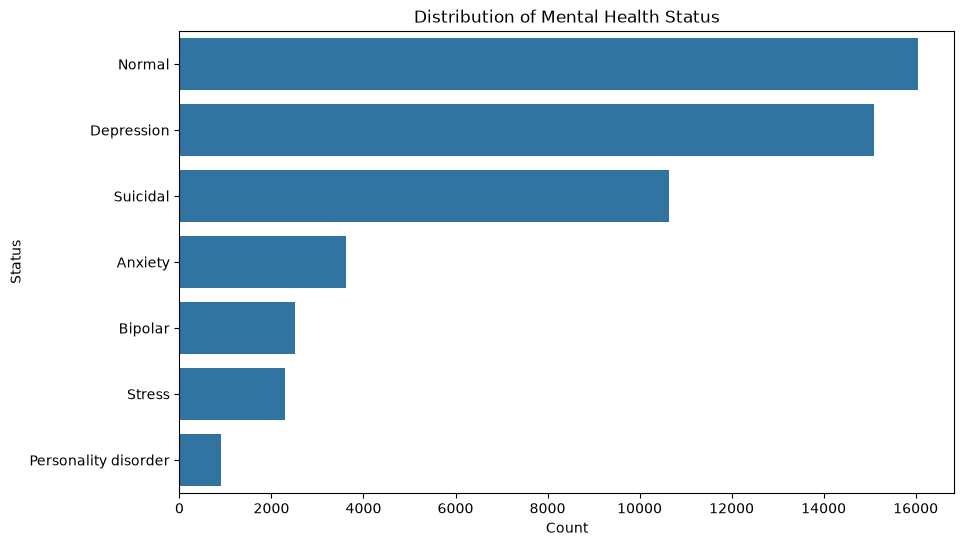

In [12]:
print(df['status'].value_counts())

plt.figure(figsize=(10,6))
sns.countplot(data=df, y='status', order=df['status'].value_counts().index)
plt.title('Distribution of Mental Health Status')
plt.xlabel('Count')
plt.ylabel('Status')
plt.show()

mood_category
Going Through a Tough Time    18490
Feeling Good                  16040
You're not Alone              10644
A Bit Overwhelmed              5919
Name: count, dtype: int64


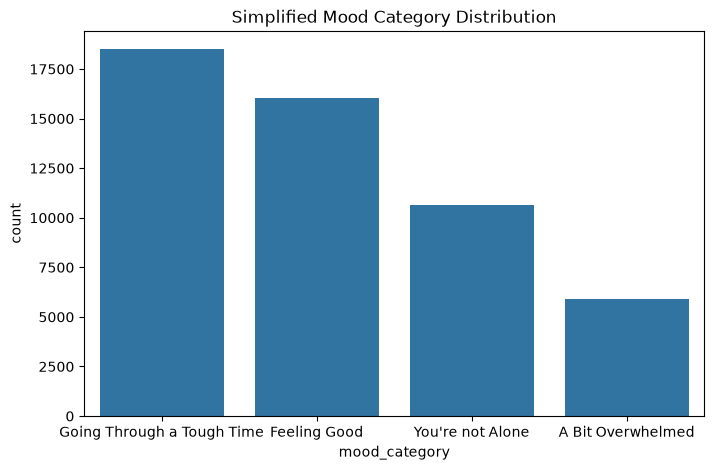

In [13]:
mood_mapping = {
    'Normal': 'Feeling Good',
    'Anxiety': 'A Bit Overwhelmed',
    'Stress': 'A Bit Overwhelmed',
    'Depression': 'Going Through a Tough Time',
    'Bipolar': 'Going Through a Tough Time',
    'Personality disorder': 'Going Through a Tough Time',
    'Suicidal': "You're not Alone",
}

df['mood_category'] = df['status'].map(mood_mapping)

print(df['mood_category'].value_counts())

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='mood_category', order=df['mood_category'].value_counts().index)
plt.title('Simplified Mood Category Distribution')
plt.show()

In [14]:
df.to_csv('../Data/cleaned_data.csv', index=False)
print("Saved! Columns:", df.columns.tolist())

Saved! Columns: ['statement', 'status', 'clean_statement', 'mood_category']
